In [1]:
import pandas as pd
import numpy as np
np.random.seed(0)
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.utils import resample
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, roc_curve, auc
from sklearn.exceptions import ConvergenceWarning, UndefinedMetricWarning
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import confusion_matrix
import warnings

In [6]:
data = pd.read_csv("data/Android_Malware.csv")

C:\Users\emon1\AppData\Local\Temp\ipykernel_1872\3292960115.py:1: DtypeWarning: Columns (56,58,63) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("data/Android_Malware.csv")


In [7]:
data.head()

,Unnamed: 0,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,0,172.217.6.202-10.42.0.211-443-50004-6,10.42.0.211,50004,172.217.6.202,443.0,6.0,13/06/2017 11:52:39,37027,1,...,32.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Android_Adware
1,1,172.217.6.202-10.42.0.211-443-35455-6,10.42.0.211,35455,172.217.6.202,443.0,6.0,13/06/2017 11:52:39,36653,1,...,32.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Android_Adware
2,2,131.253.61.68-10.42.0.211-443-51775-6,10.42.0.211,51775,131.253.61.68,443.0,6.0,13/06/2017 11:52:42,534099,8,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Android_Adware
3,3,131.253.61.68-10.42.0.211-443-51775-6,10.42.0.211,51775,131.253.61.68,443.0,6.0,13/06/2017 11:52:43,9309,3,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Android_Adware
4,4,131.253.61.68-10.42.0.211-443-51776-6,10.42.0.211,51776,131.253.61.68,443.0,6.0,13/06/2017 11:52:42,19890496,8,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Android_Adware


In [8]:
data = data.drop(' Timestamp', axis=1)

In [9]:
data.head()

,Unnamed: 0,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,0,172.217.6.202-10.42.0.211-443-50004-6,10.42.0.211,50004,172.217.6.202,443.0,6.0,37027,1,1,...,32.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Android_Adware
1,1,172.217.6.202-10.42.0.211-443-35455-6,10.42.0.211,35455,172.217.6.202,443.0,6.0,36653,1,1,...,32.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Android_Adware
2,2,131.253.61.68-10.42.0.211-443-51775-6,10.42.0.211,51775,131.253.61.68,443.0,6.0,534099,8,12,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Android_Adware
3,3,131.253.61.68-10.42.0.211-443-51775-6,10.42.0.211,51775,131.253.61.68,443.0,6.0,9309,3,0,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Android_Adware
4,4,131.253.61.68-10.42.0.211-443-51776-6,10.42.0.211,51776,131.253.61.68,443.0,6.0,19890496,8,6,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Android_Adware


In [10]:
print(data.columns.tolist())

['Unnamed: 0', 'Flow ID', ' Source IP', ' Source Port', ' Destination IP', ' Destination Port', ' Protocol', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', 

In [11]:
print(data['Label'].value_counts())

Label
Android_Adware         147443
Android_Scareware      117082
Android_SMS_Malware     67397
Benign                  23708
Name: count, dtype: int64


In [12]:
names=sorted(data['Label'].unique().tolist())
print(names)

['Android_Adware', 'Android_SMS_Malware', 'Android_Scareware', 'Benign']


In [15]:
data.columns

Index(['Unnamed: 0', 'Flow ID', ' Source IP', ' Source Port',
       ' Destination IP', ' Destination Port', ' Protocol', ' Flow Duration',
       ' Total Fwd Packets', ' Total Backward Packets',
       'Total Length of Fwd Packets', ' Total Length of Bwd Packets',
       ' Fwd Packet Length Max', ' Fwd Packet Length Min',
       ' Fwd Packet Length Mean', ' Fwd Packet Length Std',
       'Bwd Packet Length Max', ' Bwd Packet Length Min',
       ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s',
       ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max',
       ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std',
       ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean',
       ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags',
       ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags',
       ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s',
       ' Bwd Packets/s', ' Min Packet Length', ' Max Pa

In [16]:
def labelencoder(df):
    for c in df.columns:
        if df[c].dtype == 'object':
            df[c] = df[c].fillna('N')
            lbl = LabelEncoder()
            lbl.fit(list(df[c].values))
            df[c] = lbl.transform(df[c].values)
    return df

data1 = labelencoder(data)
data1.dropna(axis=0, inplace=True)

# Find missing values
missing_values = data1.isna().sum()
print(missing_values)

Unnamed: 0         0
Flow ID            0
 Source IP         0
 Source Port       0
 Destination IP    0
                  ..
Idle Mean          0
 Idle Std          0
 Idle Max          0
 Idle Min          0
Label              0
Length: 85, dtype: int64


In [17]:
print(data1.dtypes)

Unnamed: 0           int64
Flow ID              int32
 Source IP           int32
 Source Port         int64
 Destination IP      int32
                    ...   
Idle Mean          float64
 Idle Std          float64
 Idle Max          float64
 Idle Min          float64
Label                int32
Length: 85, dtype: object


In [18]:
data1

,Unnamed: 0,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,0,133842,10,50004,1285,443.0,6.0,37027,1,1,...,32.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,1,133816,10,35455,1285,443.0,6.0,36653,1,1,...,32.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,2,111350,10,51775,649,443.0,6.0,534099,8,12,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,3,111350,10,51775,649,443.0,6.0,9309,3,0,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
4,4,111351,10,51776,649,443.0,6.0,19890496,8,6,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
355625,405,135200,718,80,18,38405.0,6.0,126711,1,1,...,32.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3
355626,406,72469,10,7632,16,53.0,17.0,48012,1,1,...,32.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3
355627,407,75843,10,45970,100,443.0,6.0,20028018,11,8,...,20.0,367528.0,0.0,367528.0,367528.0,19660490.0,0.0,19660490.0,19660490.0,3
355628,408,65109,10,51982,16,53.0,17.0,347926,1,1,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3


In [19]:
print("Total Features : ",len(data1.columns)-1)

Total Features :  84


In [20]:
from sklearn.utils import resample

def balance_data(data, random_state=0):
    X = data.drop("Label", axis=1)
    y = data["Label"]
    class_counts = y.value_counts()
    minority_class_count = class_counts.min()
    balanced_data = pd.DataFrame(columns=data.columns)

    for label in class_counts.index:
        class_samples = data[data["Label"] == label]
        resampled_samples = resample(class_samples,
                                     replace=True,
                                     n_samples=minority_class_count,
                                     random_state=random_state)
        balanced_data = pd.concat([balanced_data, resampled_samples])

    balanced_data = balanced_data.sample(frac=1, random_state=random_state)

    return balanced_data

In [21]:
balanced_data = balance_data(data1)
balanced_class_counts = balanced_data["Label"].value_counts()
print(balanced_class_counts)

C:\Users\emon1\AppData\Local\Temp\ipykernel_1872\507299223.py:16: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_data = pd.concat([balanced_data, resampled_samples])


Label
0    23708
2    23708
3    23708
1    23708
Name: count, dtype: int64


In [22]:
from sklearn.model_selection import train_test_split 
train_x,test_x,train_y,test_y = train_test_split(data[data.columns[:len(data.columns)-1]].to_numpy(), data[data.columns[-1]].to_numpy(), test_size = 0.2, shuffle=True)

In [23]:
print("Train features size : ",len(train_x))
print("Train labels size : ",len(train_y))
print("Test features size : ",len(test_x))
print("Test features size : ",len(test_y))

Train features size :  284500
Train labels size :  284500
Test features size :  71126
Test features size :  71126


In [24]:
print("Train features : ",train_x.shape)
print("Train labels : ",train_y.shape)
print("Test Features : ",test_x.shape)
print("Test labels : ",test_y.shape)

Train features :  (284500, 84)
Train labels :  (284500,)
Test Features :  (71126, 84)
Test labels :  (71126,)


<Axes: title={'center': 'Correlation Heatmap of the Dataset'}>

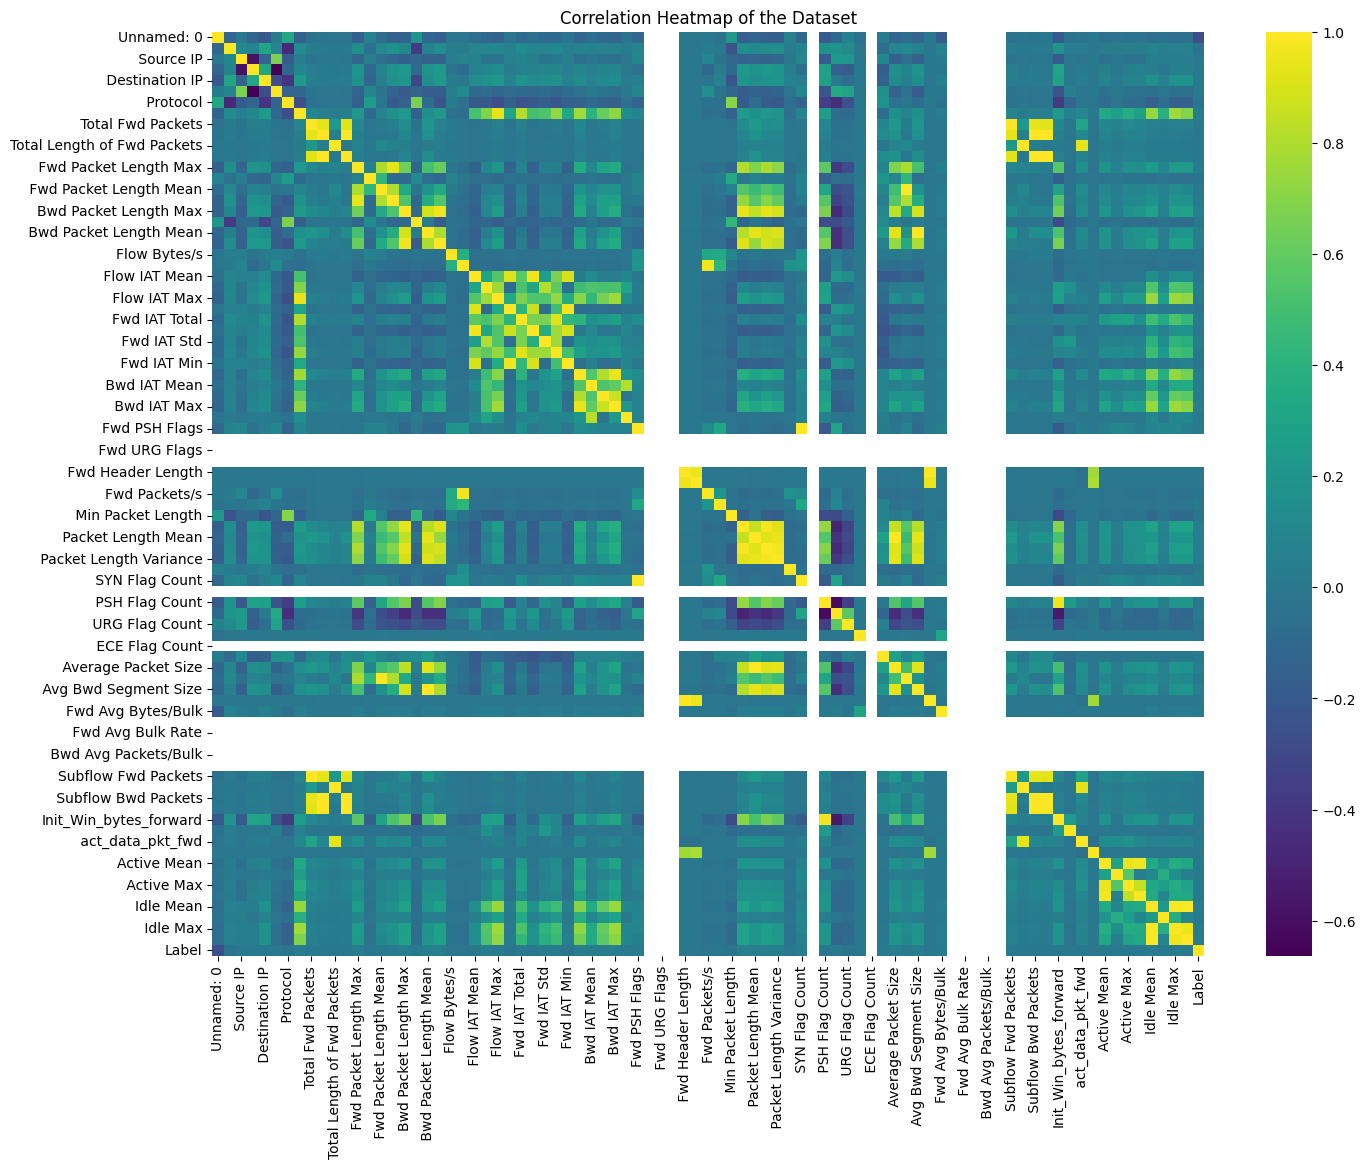

In [26]:
plt.figure(figsize=(16,12))
plt.title("Correlation Heatmap of the Dataset")
sns.heatmap(data.corr(), cmap="viridis", annot=False)

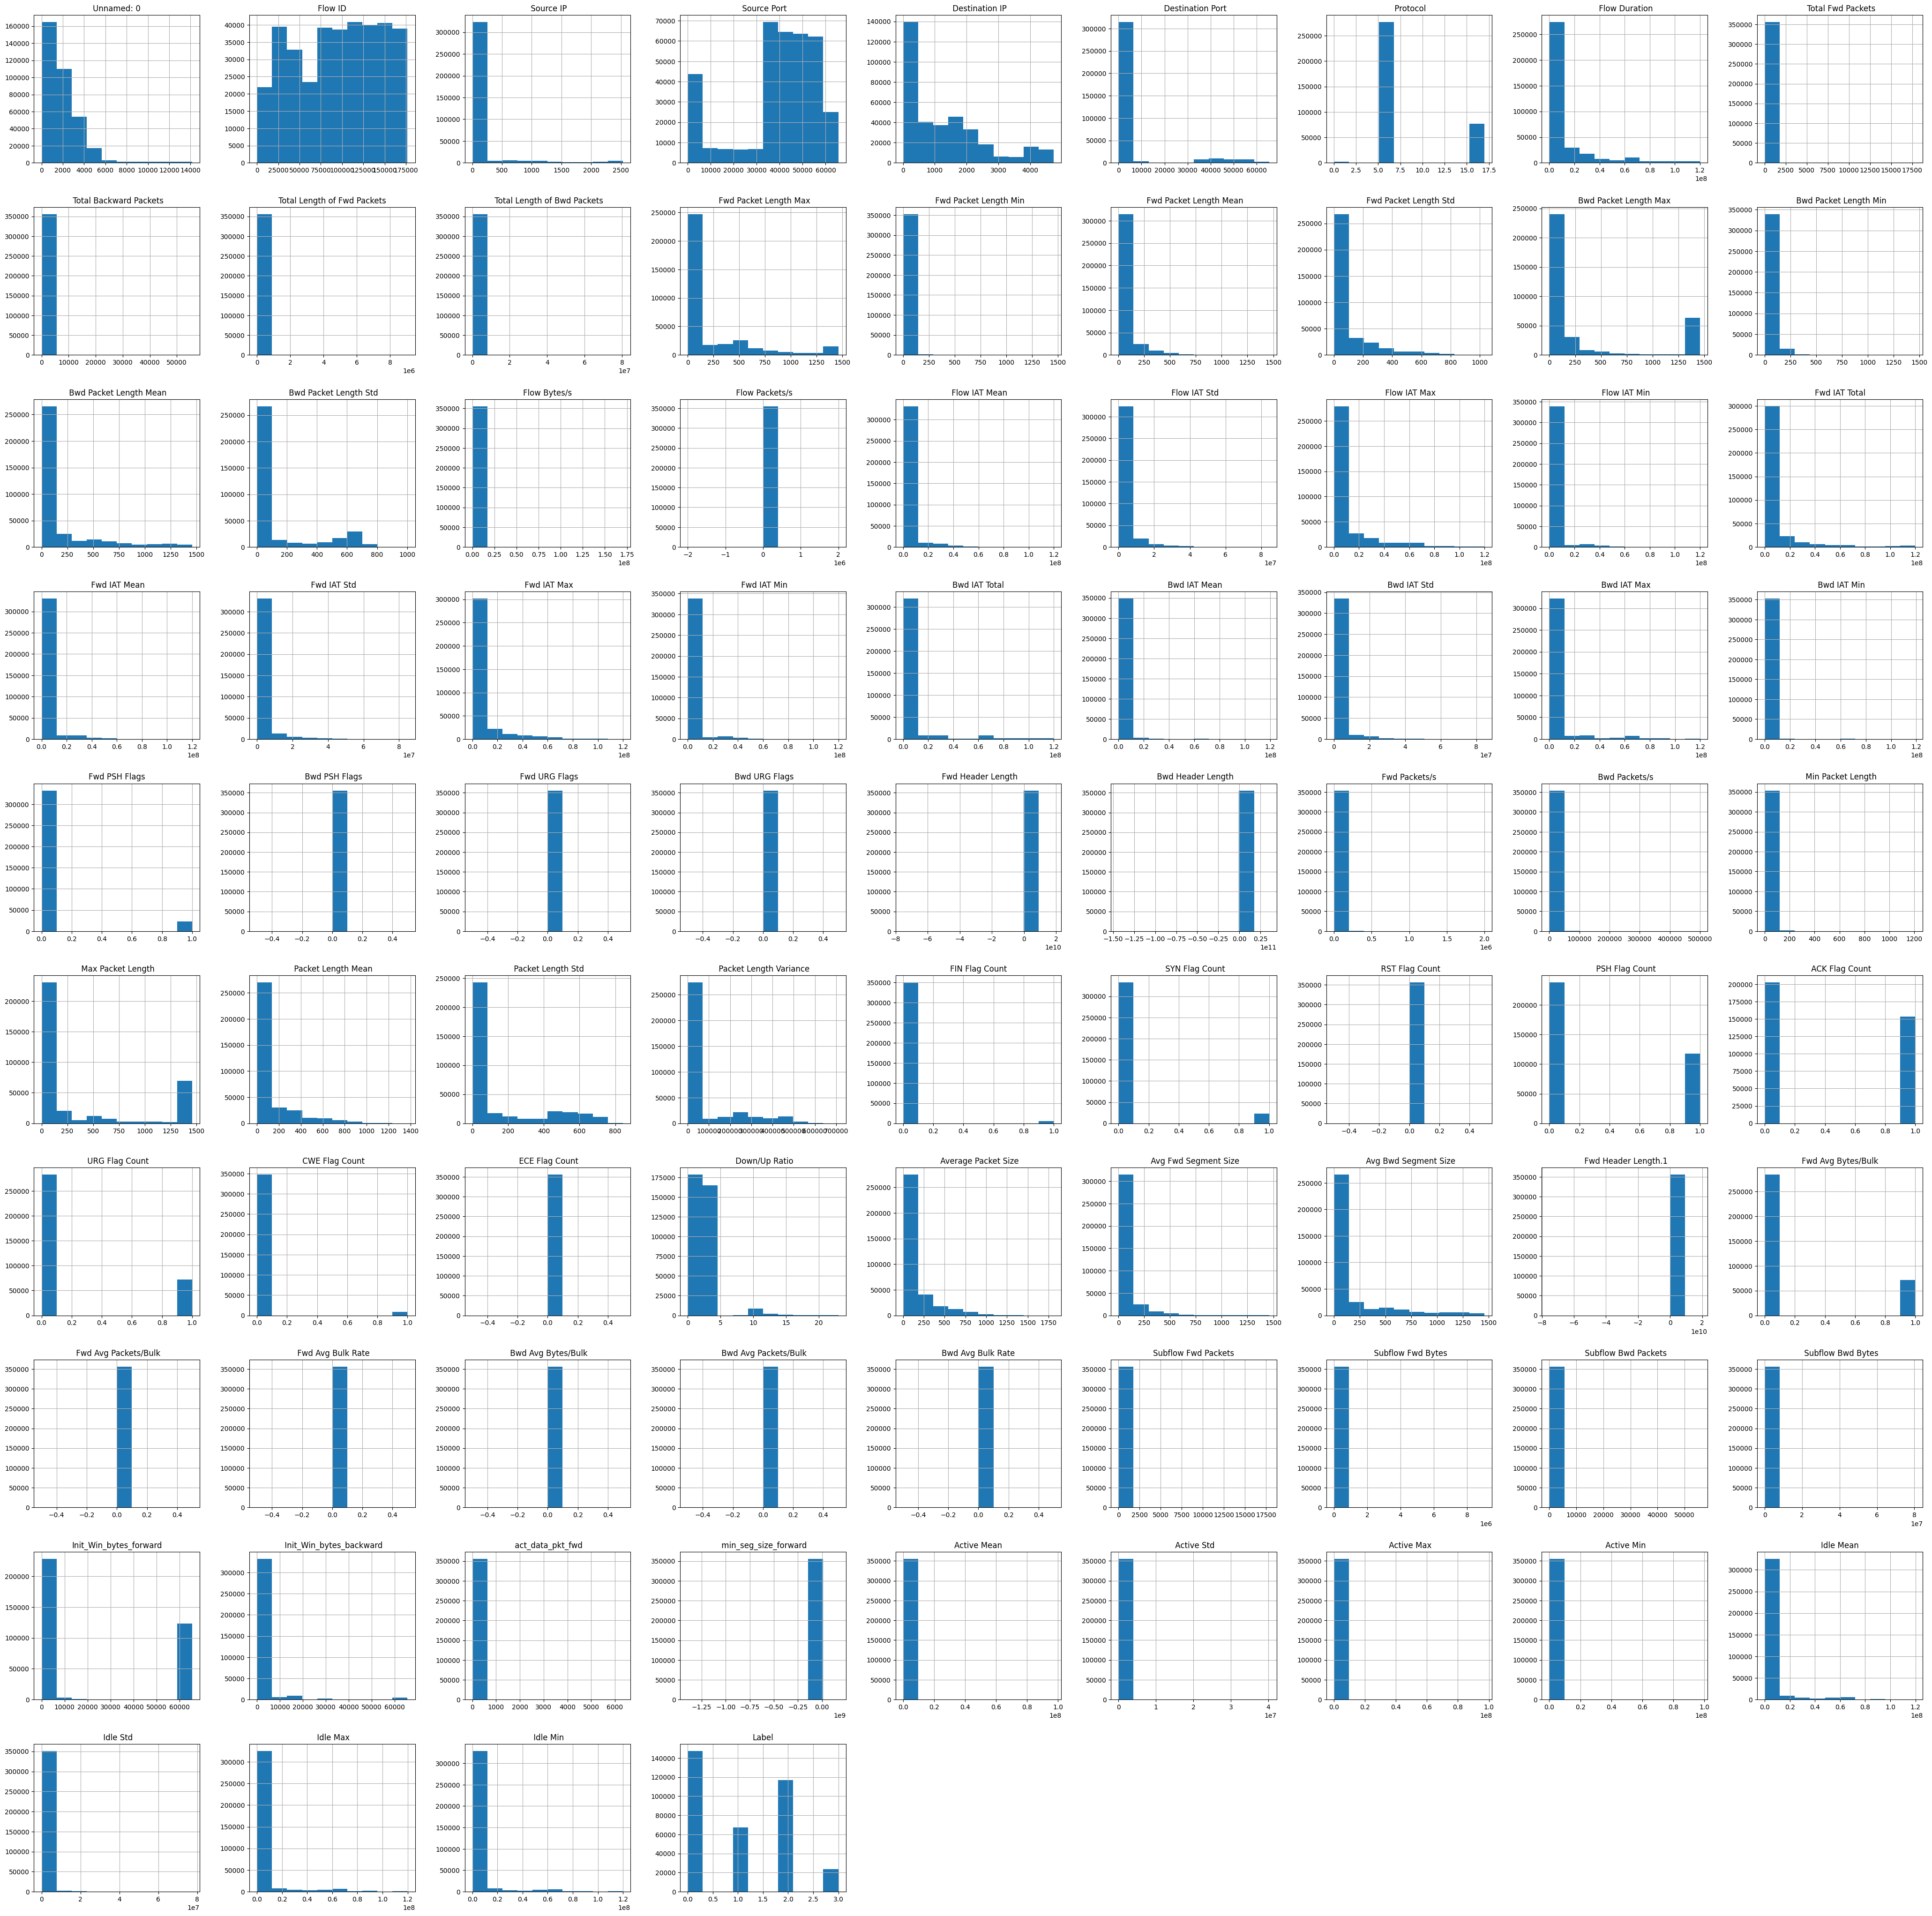

In [28]:
data1.hist(bins=10, figsize=(52,52))
plt.show()

In [27]:
data.head(2)

,Unnamed: 0,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,0,133842,10,50004,1285,443.0,6.0,37027,1,1,...,32.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,1,133816,10,35455,1285,443.0,6.0,36653,1,1,...,32.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


In [29]:
X = data.drop('Label', axis=1)  # Features
y = data['Label']  # Target variable

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Feature Importance:
Fwd Avg Bytes/Bulk: 0.2463395789748616
Unnamed: 0: 0.09449186385804358
Flow ID: 0.055225220666414304
 Source Port: 0.036450820111580136
 Destination IP: 0.03223617626480341
 Source IP: 0.030694941539139126
 Flow IAT Min: 0.02605043194565974
 Flow IAT Max: 0.025328911839197343
 Flow Duration: 0.024942770210559496
 Flow IAT Mean: 0.024240070152057366
Fwd Packets/s: 0.024144830069526245
 Flow Packets/s: 0.02404314042390198
 Fwd IAT Min: 0.01778424080699036
 Bwd Packets/s: 0.016550234170436728
Init_Win_bytes_forward: 0.016082041052758334
 Fwd IAT Max: 0.015480110152729029
Fwd IAT Total: 0.015351188869398454
 Fwd IAT Mean: 0.015062408944830937
 CWE Flag Count: 0.013271503622505261
Flow Bytes/s: 0.012410524329041476
 Destination Port: 0.011971122504177163
 Flow IAT Std: 0.00974456021497749
 Init_Win_bytes_backward: 0.009306905553374501
 Fwd IAT Std: 0.00858196545103732
 Down/Up Ratio: 0.007282921875325569
 Average Packet Size: 0.007051717389629899
 Packet Length Std: 0.00

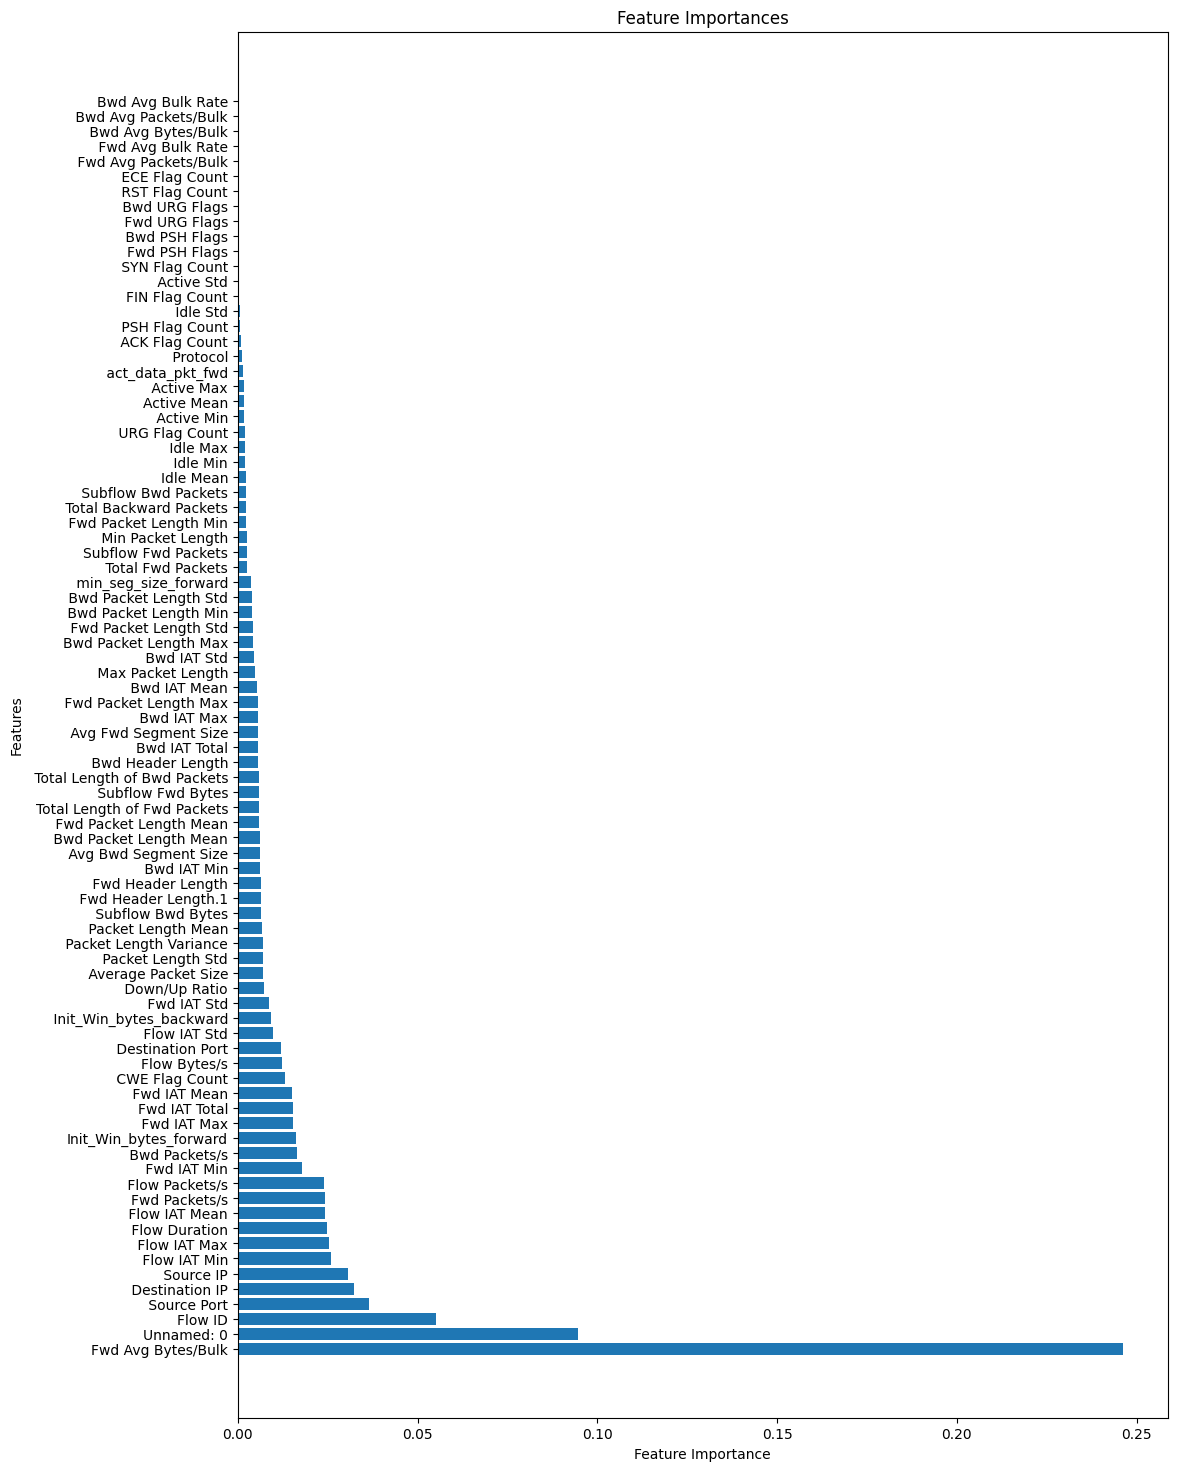

In [31]:
random_forest_model = RandomForestClassifier(random_state=42)
random_forest_model.fit(X_train, y_train)
feature_importance = random_forest_model.feature_importances_
feature_importance_dict = dict(zip(X_train.columns, feature_importance))
sorted_feature_importance = sorted(feature_importance_dict.items(), key=lambda x: x[1], reverse=True)

print("Feature Importance:")
for feature, importance in sorted_feature_importance:
    print(f"{feature}: {importance}")

features, importance = zip(*sorted_feature_importance)
plt.figure(figsize=(12, 18))
plt.barh(features, importance)
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Feature Importances')
plt.show()


Gradient Boosting Model:


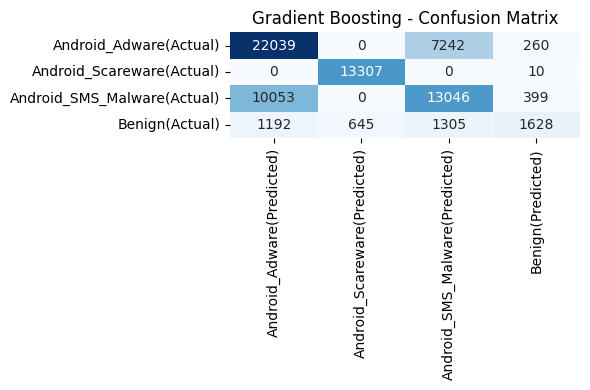

Gradient Boosting Classification Report:
               precision    recall  f1-score   support

           0       0.66      0.75      0.70     29541
           1       0.95      1.00      0.98     13317
           2       0.60      0.56      0.58     23498
           3       0.71      0.34      0.46      4770

    accuracy                           0.70     71126
   macro avg       0.73      0.66      0.68     71126
weighted avg       0.70      0.70      0.70     71126


Random Forest Model:


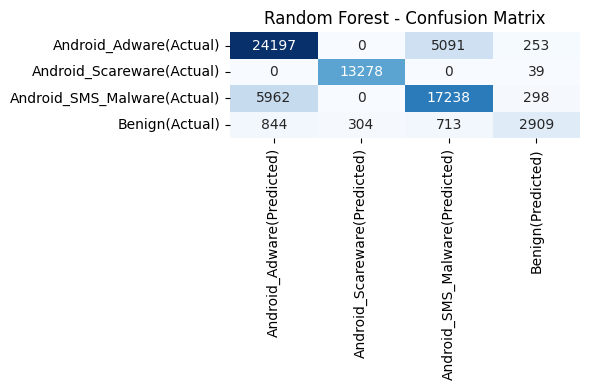

Random Forest Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.82      0.80     29541
           1       0.98      1.00      0.99     13317
           2       0.75      0.73      0.74     23498
           3       0.83      0.61      0.70      4770

    accuracy                           0.81     71126
   macro avg       0.83      0.79      0.81     71126
weighted avg       0.81      0.81      0.81     71126


AdaBoost Model:


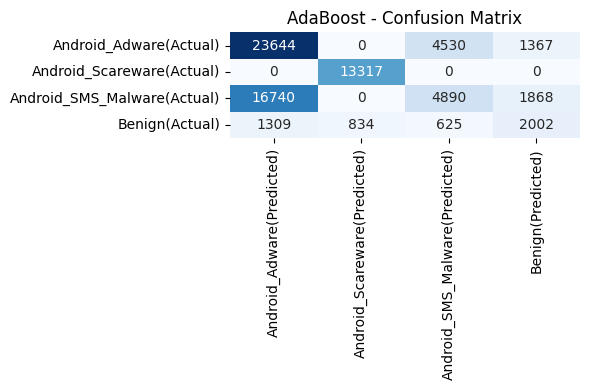

AdaBoost Classification Report:
               precision    recall  f1-score   support

           0       0.57      0.80      0.66     29541
           1       0.94      1.00      0.97     13317
           2       0.49      0.21      0.29     23498
           3       0.38      0.42      0.40      4770

    accuracy                           0.62     71126
   macro avg       0.59      0.61      0.58     71126
weighted avg       0.60      0.62      0.58     71126


Decision Tree Model:


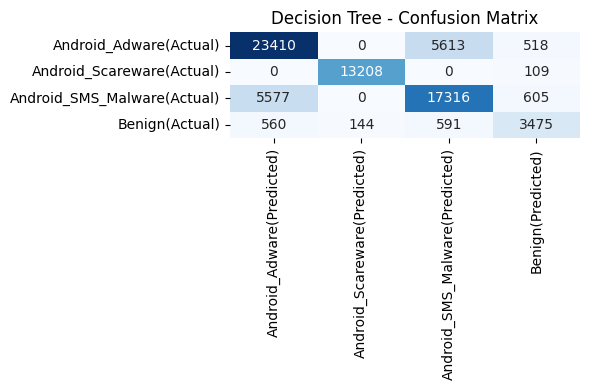

Decision Tree Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.79      0.79     29541
           1       0.99      0.99      0.99     13317
           2       0.74      0.74      0.74     23498
           3       0.74      0.73      0.73      4770

    accuracy                           0.81     71126
   macro avg       0.81      0.81      0.81     71126
weighted avg       0.81      0.81      0.81     71126


Multi-layer Perceptron Model:


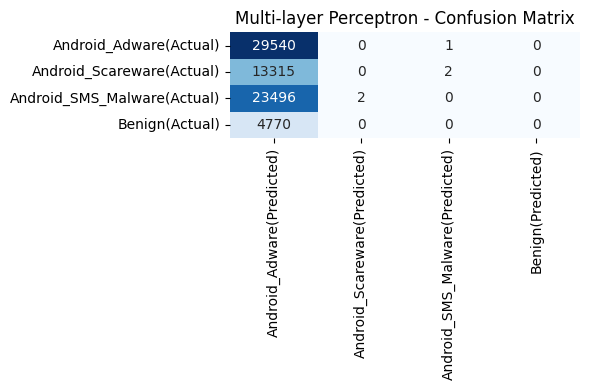

Multi-layer Perceptron Classification Report:
               precision    recall  f1-score   support

           0       0.42      1.00      0.59     29541
           1       0.00      0.00      0.00     13317
           2       0.00      0.00      0.00     23498
           3       0.00      0.00      0.00      4770

    accuracy                           0.42     71126
   macro avg       0.10      0.25      0.15     71126
weighted avg       0.17      0.42      0.24     71126


Bagging Classifier Model:


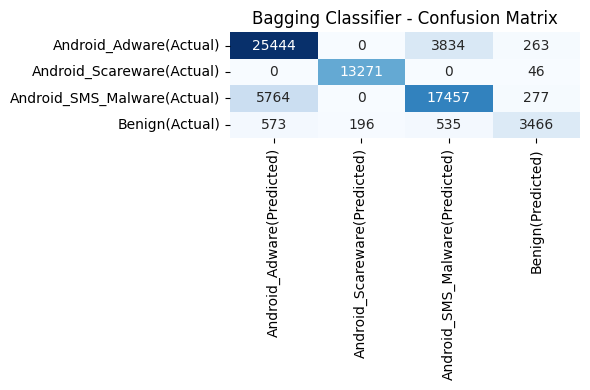

Bagging Classifier Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.86      0.83     29541
           1       0.99      1.00      0.99     13317
           2       0.80      0.74      0.77     23498
           3       0.86      0.73      0.79      4770

    accuracy                           0.84     71126
   macro avg       0.86      0.83      0.84     71126
weighted avg       0.84      0.84      0.84     71126


Logistic Regression Model:


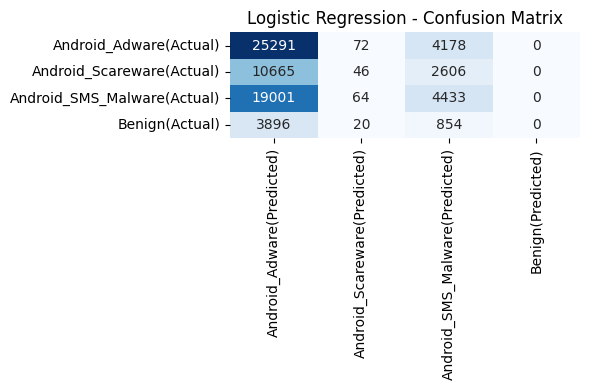

Logistic Regression Classification Report:
               precision    recall  f1-score   support

           0       0.43      0.86      0.57     29541
           1       0.23      0.00      0.01     13317
           2       0.37      0.19      0.25     23498
           3       0.00      0.00      0.00      4770

    accuracy                           0.42     71126
   macro avg       0.26      0.26      0.21     71126
weighted avg       0.34      0.42      0.32     71126


K-Nearest Neighbors Model:


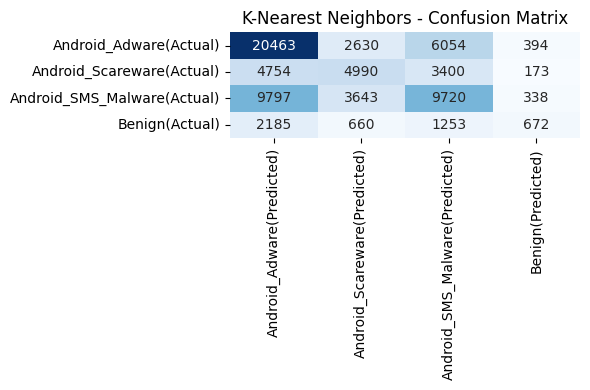

K-Nearest Neighbors Classification Report:
               precision    recall  f1-score   support

           0       0.55      0.69      0.61     29541
           1       0.42      0.37      0.40     13317
           2       0.48      0.41      0.44     23498
           3       0.43      0.14      0.21      4770

    accuracy                           0.50     71126
   macro avg       0.47      0.41      0.42     71126
weighted avg       0.49      0.50      0.49     71126


Naive Bayes (Gaussian) Model:


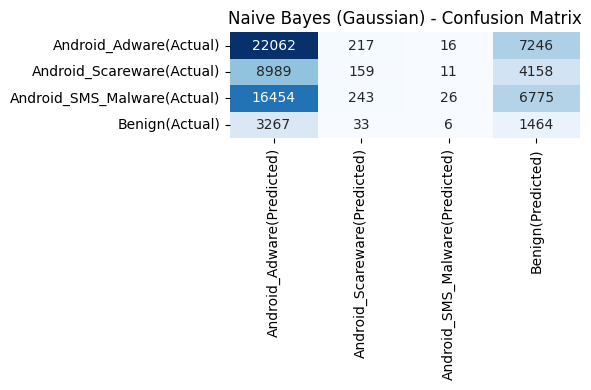

Naive Bayes (Gaussian) Classification Report:
               precision    recall  f1-score   support

           0       0.43      0.75      0.55     29541
           1       0.24      0.01      0.02     13317
           2       0.44      0.00      0.00     23498
           3       0.07      0.31      0.12      4770

    accuracy                           0.33     71126
   macro avg       0.30      0.27      0.17     71126
weighted avg       0.38      0.33      0.24     71126



C:\Users\emon1\AppData\Local\Temp\ipykernel_1872\1237421228.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(accuracy_scores.keys()), y=list(accuracy_scores.values()), palette='viridis')


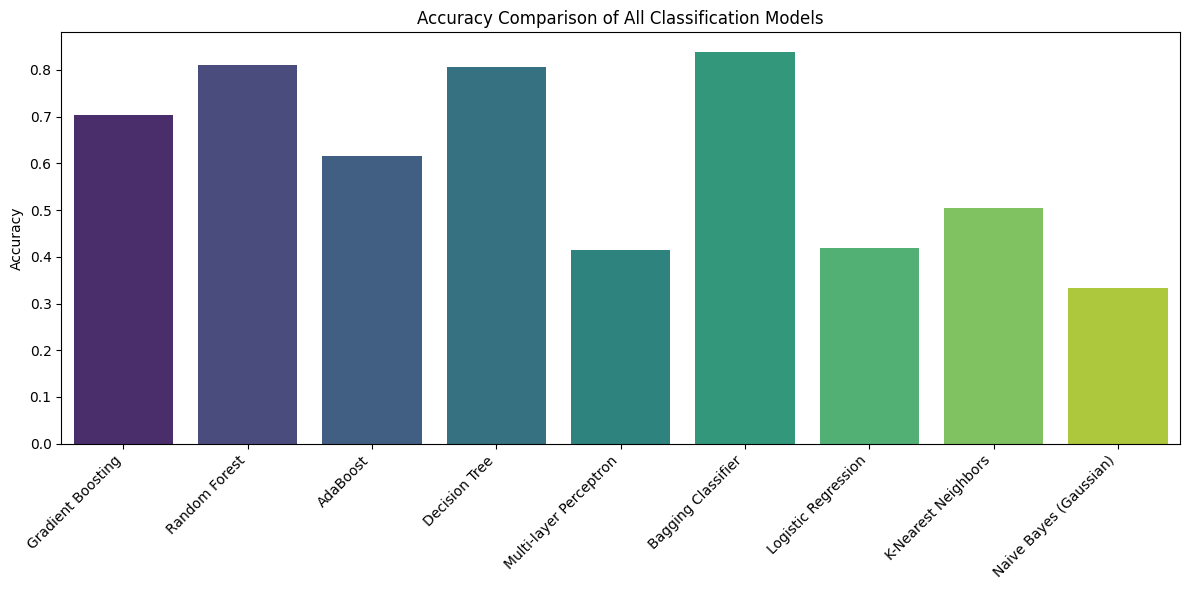

In [33]:
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, AdaBoostClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.exceptions import ConvergenceWarning, UndefinedMetricWarning

# Ignore specific warnings
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

# Define all models
models = {
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Multi-layer Perceptron': MLPClassifier(random_state=42),
    'Bagging Classifier': BaggingClassifier(estimator=DecisionTreeClassifier(), random_state=42),
    'Logistic Regression': LogisticRegression(random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Naive Bayes (Gaussian)': GaussianNB(),
}

# Dictionary to hold accuracy scores
accuracy_scores = {}

# Loop through models
for model_name, model in models.items():
    print(f"\n{model_name} Model:")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Accuracy score calculation
    acc = accuracy_score(y_test, y_pred)
    accuracy_scores[model_name] = acc

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Android_Adware(Predicted)', 'Android_Scareware(Predicted)', 'Android_SMS_Malware(Predicted)', 'Benign(Predicted)'],
                yticklabels=['Android_Adware(Actual)', 'Android_Scareware(Actual)', 'Android_SMS_Malware(Actual)', 'Benign(Actual)'])
    plt.title(f"{model_name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()

    # Classification Report
    classification_rep = classification_report(y_test, y_pred)
    print(f"{model_name} Classification Report:\n", classification_rep)

# ======== Accuracy Bar Chart ========== #
plt.figure(figsize=(12, 6))
sns.barplot(x=list(accuracy_scores.keys()), y=list(accuracy_scores.values()), palette='viridis')
plt.xticks(rotation=45, ha='right')
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison of All Classification Models")
plt.tight_layout()
plt.show()